# Assignment 3: EDA & Data Description of the A-OKVQA Dataset

**This notebook**
- Serves as the **data description and EDA** part of the **M1 Proposal** for Assignment 3.
- Checks the dataset for missing data, label problems and image leakage, and tests simple text-only baselines.

A-OKVQA is a visual question answering dataset. Each question comes with a COCO photo, four answer choices, one correct choice, ten free-text answers and three rationales.

## 0. Setup

Import the tools and set the paths. Figures are also saved as PNG for the report.

In [1]:
from pathlib import Path
from collections import Counter
from io import BytesIO
import hashlib
import re
import sys
import textwrap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
import sklearn
import torch
from PIL import Image

SEED = 42
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'Assignment3' else ROOT
sys.path.insert(0, str(ROOT / 'Assignment3'))
FIG_DIR = ROOT.parent / 'latex' / 'a3_m1_report' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 12, 'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'legend.fontsize': 10})
pd.set_option('display.width', 160)

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')

pd.Series({'Python': sys.version.split()[0], 'NumPy': np.__version__, 'pandas': pd.__version__,
           'Matplotlib': matplotlib.__version__, 'Pillow': PIL.__version__, 'scikit-learn': sklearn.__version__,
           'PyTorch': torch.__version__}, name='Version').to_frame()

,Version
Python,3.12.16
NumPy,2.5.3
pandas,3.0.5
Matplotlib,3.11.2
Pillow,13.0.0
scikit-learn,1.9.1
PyTorch,2.14.0+cu130


**Observation and comment**

The table lists the library versions used for the outputs below. Figures are saved as PNG in the report folder as well.

## 1. Read the dataset

The data is `HuggingFaceM4/A-OKVQA` at revision `d1b0efa`. The test split has no labels, so only the official train and validation splits are read as labelled data.

In [2]:
from data_loader import read_aokvqa, read_split, make_split, shared_keys, REVISION, SPLITS
rows = []
for s in SPLITS:
    part = read_split(s)
    labelled = part['correct_choice_idx'].notna().sum()
    keys = [hashlib.md5(item['bytes']).hexdigest() for item in part['image']]
    rows.append({'split': s, 'questions': len(part), 'labelled': labelled, 'unlabelled': len(part) - labelled,
                 'distinct images': len(set(keys))})
    del part
pd.DataFrame(rows).set_index('split')

,questions,labelled,unlabelled,distinct images
split,,,,
train,17056,17056,0,16539
validation,1145,1145,0,1122
test,6702,0,6702,6030


In [3]:
df = read_aokvqa()
per_image = df.groupby(['source_split', 'image_key']).size()
table = per_image.groupby('source_split').describe().round(2)
display(table)
display(per_image.groupby('source_split').value_counts().unstack(0).fillna(0).astype(int).head(8))
shared = shared_keys(df)
print('images shared between official train and validation:', len(shared))
print('questions on those images:', df['image_key'].isin(shared).sum())

,count,mean,std,min,25%,50%,75%,max
source_split,,,,,,,,
train,16539.0,1.03,0.17,1.0,1.0,1.0,1.0,2.0
validation,1122.0,1.02,0.14,1.0,1.0,1.0,1.0,2.0


source_split,train,validation
1,16022,1099
2,517,23


images shared between official train and validation: 0
questions on those images: 0


**Observation and comment**

The official train split has 17,056 questions on 16,539 distinct images, and the official validation split has 1,145 questions on 1,122 images. Both are fully labelled. The test split has 6,702 questions on 6,030 images and none of them has a label, so it cannot be used for evaluation. Almost every image has one question: the mean is 1.03 per image in train and 1.02 in validation, and the maximum is 2. In train, 16,022 images have one question and 517 have two. In validation, 1,099 have one and 23 have two. No image is shared between the official train and validation splits (0 shared images, 0 questions affected), so nothing had to be dropped. Images are still grouped when we split, because 517 train images carry two questions.

## 2. Our split

Our test set is the official validation split. The official train split is cut into train and validation by image hash, so all questions of one image stay together.

In [4]:
manifest = make_split(df, SEED)
df = df.merge(manifest[['question_id', 'split']], on='question_id', how='left')
counts = manifest.groupby('split').agg(questions=('question_id', 'count'), images=('image_key', 'nunique')).loc[list(SPLITS)]
counts.loc['Total'] = counts.sum()
counts['share of questions (%)'] = (counts['questions'] / counts.loc['Total', 'questions'] * 100).round(1)
display(counts)
keys = {s: set(manifest.loc[manifest['split'] == s, 'image_key']) for s in SPLITS}
print('train & validation:', len(keys['train'] & keys['validation']), '| train & test:', len(keys['train'] & keys['test']),
      '| validation & test:', len(keys['validation'] & keys['test']))
print('questions dropped:', df['split'].isna().sum())
df['difficult_direct_answer'].groupby(df['split']).agg(['sum', 'mean']).loc[list(SPLITS)].round(4)

,questions,images,share of questions (%)
split,,,
train,15346,14885,84.3
validation,1710,1654,9.4
test,1145,1122,6.3
Total,18201,17661,100.0


train & validation: 0 | train & test: 0 | validation & test: 0
questions dropped: 0


,sum,mean
split,,
train,1397,0.0910
validation,147,0.0860
test,70,0.0611


**Observation and comment**

Our split has 15,346 train questions (14,885 images, 84.3%), 1,710 validation questions (1,654 images, 9.4%) and 1,145 test questions (1,122 images, 6.3%), 18,201 in total on 17,661 images. The test set is the official validation split. No image appears in two splits (0 overlaps for each pair) and no question was dropped. The manifest is saved as `Assignment3/splits.csv`. The share of questions flagged `difficult_direct_answer` is 9.1% in train (1,397), 8.6% in validation (147) and 6.1% in test (70). The test share is a bit lower than the other two.

In [5]:
lab = df[df['split'].notna()].copy()
train = lab[lab['split'] == 'train']
val = lab[lab['split'] == 'validation']
test = lab[lab['split'] == 'test']
len(lab), len(train), len(val), len(test)

(18201, 15346, 1710, 1145)

## 3. Missing modality and validity

Check that every row has an image, a question, four sensible choices and a valid label. Rates are over the 18,201 labelled questions.

In [6]:
def decodes(data):
    try:
        Image.open(BytesIO(data)).convert('RGB')
        return True
    except Exception:
        return False

n = len(lab)
choices = lab['choices'].tolist()
checks = {
    'image missing': lab['image'].isna().sum(),
    'image cannot be decoded': sum(not decodes(b) for b in lab['image']),
    'empty question': (lab['question'].fillna('').str.strip() == '').sum(),
    'not exactly 4 choices': sum(len(c) != 4 for c in choices),
    'empty choice': sum(any(str(x).strip() == '' for x in c) for c in choices),
    'duplicate choices': sum(len(set(x.lower().strip() for x in c)) < len(c) for c in choices),
    'label outside 0..3': (~lab['correct_choice_idx'].isin([0, 1, 2, 3])).sum(),
    'direct answers not 10': sum(len(d) != 10 for d in lab['direct_answers']),
    'empty direct answer': sum(any(str(x).strip() == '' for x in d) for d in lab['direct_answers']),
    'rationales not 3': sum(len(r) != 3 for r in lab['rationales']),
    'empty rationale': sum(any(str(x).strip() == '' for x in r) for r in lab['rationales']),
    'duplicate question_id': lab['question_id'].duplicated().sum(),
}
pd.DataFrame({'count': checks, 'rate (%)': {k: round(v / n * 100, 3) for k, v in checks.items()}})

,count,rate (%)
image missing,0,0.000
image cannot be decoded,0,0.000
empty question,0,0.000
not exactly 4 choices,0,0.000
empty choice,7,0.038
duplicate choices,37,0.203
label outside 0..3,0,0.000
direct answers not 10,0,0.000
empty direct answer,2,0.011
rationales not 3,0,0.000


**Observation and comment**

There are no missing or undecodable images, no empty questions, and every question has exactly 4 choices, a label in 0..3, 10 direct answers and 3 rationales. There are no duplicate question ids. Small problems: 7 questions (0.038%) have an empty choice, 37 (0.203%) have two identical choices, and 2 (0.011%) have an empty direct answer. These rows are few, so we keep them. Note that `direct_answers` is stored as a string such as "['cigarette', ...]" in the parquet, and the loader turns it back into a list.

## 4. Images

Read the image headers to get the original size, mode and file size before the resize to 224 x 224. Each distinct image is counted once.

,width,height,aspect,kb
count,17661.00,17661.00,17661.00,17661.00
mean,586.83,481.84,1.28,52.61
std,86.37,94.32,0.34,18.63
min,160.00,120.00,0.33,4.48
25%,500.00,426.00,1.05,39.39
50%,640.00,480.00,1.33,50.39
75%,640.00,500.00,1.50,63.90
max,640.00,640.00,4.81,165.96


,,images
mode,format,
RGB,JPEG,17641
L,JPEG,20


most common sizes:


images
width height        
640   480       4005
      427       2295
480   640       1141
640   426        848
500   375        657

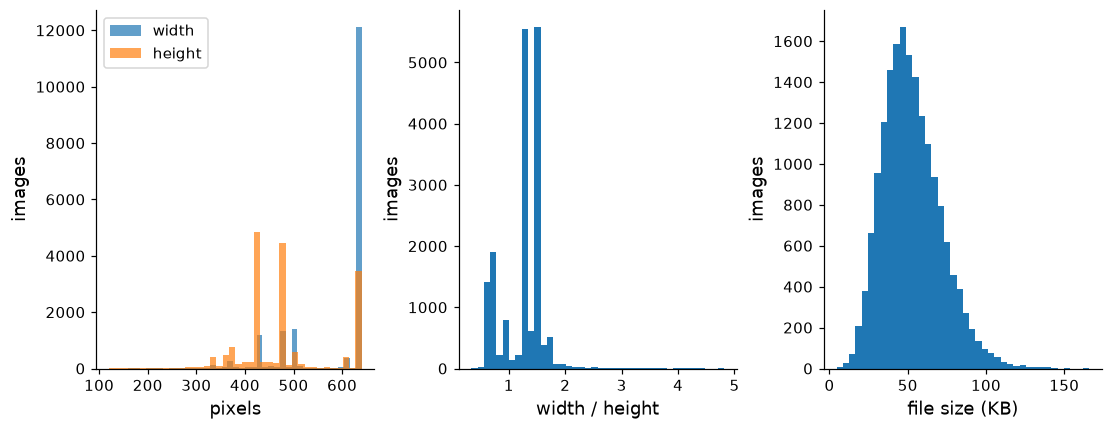

In [7]:
one = lab.drop_duplicates('image_key')
info = []
for b in one['image']:
    im = Image.open(BytesIO(b))
    info.append((im.size[0], im.size[1], im.mode, im.format, len(b) / 1024))
img = pd.DataFrame(info, columns=['width', 'height', 'mode', 'format', 'kb'])
img['aspect'] = img['width'] / img['height']
display(img[['width', 'height', 'aspect', 'kb']].describe().round(2))
display(img[['mode', 'format']].value_counts().rename('images').to_frame())
print('most common sizes:'); display(img.groupby(['width', 'height']).size().sort_values(ascending=False).head(5).rename('images').to_frame())
fig, ax = plt.subplots(1, 3, figsize=(10, 3.8), layout='constrained')
ax[0].hist(img['width'], bins=40, alpha=0.7, label='width')
ax[0].hist(img['height'], bins=40, alpha=0.7, label='height')
ax[0].set(xlabel='pixels', ylabel='images'); ax[0].legend()
ax[1].hist(img['aspect'], bins=40)
ax[1].set(xlabel='width / height', ylabel='images')
ax[2].hist(img['kb'], bins=40)
ax[2].set(xlabel='file size (KB)', ylabel='images')
save(fig, 'image_sizes.png')
plt.show()

**Observation and comment**

There are 17,661 distinct labelled images. Width has mean 586.8 and median 640 pixels, with a maximum of 640. Height has mean 481.8 and median 480, with a maximum of 640. The smallest image is 160 x 120. The most common size is 640 x 480 (4,005 images), then 640 x 427 (2,295) and 480 x 640 (1,141). Aspect ratio (width / height) has a median of 1.33 and ranges from 0.33 to 4.81. 17,641 images are RGB JPEG and 20 are grayscale (mode L) JPEG, which the loader converts to RGB. File size has mean 52.6 KB and a maximum of 166.0 KB. Resizing to 224 x 224 squeezes most images (landscape, about 4:3), so the objects get slightly stretched. We keep this simple resize because it is the same for all methods.

## 5. Text

Length of questions, choices and rationales in words, the vocabulary, and the most common question openings. A-OKVQA has no question type field, so the first words are used as a rough type.

,question,choice,direct answer,rationale
count,18201.00,72804.00,182010.00,54603.00
mean,8.81,1.27,1.24,11.11
std,3.04,0.44,0.43,6.72
min,4.00,0.00,0.00,0.00
25%,7.00,1.00,1.00,6.00
50%,8.00,1.00,1.00,9.00
75%,11.00,2.00,1.00,14.00
max,44.00,4.00,4.00,65.00


,distinct words
question,6508
choice,13456
rationale,15672
all text,21359


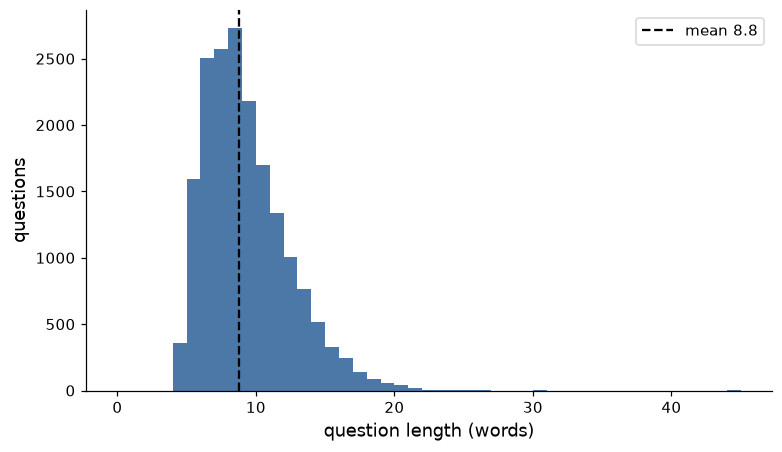

In [8]:
def words(t):
    return re.findall(r"[a-z0-9']+", t.lower())

q_len = lab['question'].map(lambda t: len(words(t)))
c_len = pd.Series([len(words(x)) for c in lab['choices'] for x in c])
r_len = pd.Series([len(words(x)) for r in lab['rationales'] for x in r])
d_len = pd.Series([len(words(x)) for d in lab['direct_answers'] for x in d])
stats = pd.DataFrame({'question': q_len.describe(), 'choice': c_len.describe(), 'direct answer': d_len.describe(),
                      'rationale': r_len.describe()}).round(2)
display(stats)
vocab = {}
for name, texts in {'question': lab['question'], 'choice': [x for c in lab['choices'] for x in c],
                    'rationale': [x for r in lab['rationales'] for x in r]}.items():
    vocab[name] = len(set(w for t in texts for w in words(t)))
all_words = set(w for t in lab['question'] for w in words(t)) | set(w for c in lab['choices'] for x in c for w in words(x)) | set(w for r in lab['rationales'] for x in r for w in words(x))
vocab['all text'] = len(all_words)
display(pd.Series(vocab, name='distinct words').to_frame())
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.hist(q_len, bins=range(0, q_len.max() + 2), color='#4c78a8')
ax.axvline(q_len.mean(), color='k', ls='--', label='mean %.1f' % q_len.mean())
ax.set(xlabel='question length (words)', ylabel='questions'); ax.legend()
save(fig, 'question_length.png')
plt.show()

In [9]:
def opening(t, k=3):
    return ' '.join(words(t)[:k])
for k in (2, 3):
    top = lab['question'].map(lambda t: opening(t, k)).value_counts().head(15)
    display(pd.DataFrame({'questions': top, 'share (%)': (top / len(lab) * 100).round(1)}).rename_axis('first %d words' % k))
first = lab['question'].map(lambda t: opening(t, 1)).value_counts().head(8)
print((first / len(lab) * 100).round(1).to_dict())

,questions,share (%)
first 2 words,,
what is,4109,22.6
what type,1102,6.1
what are,850,4.7
why is,730,4.0
how many,595,3.3
what color,542,3.0
what kind,526,2.9
what does,480,2.6
why are,404,2.2


,questions,share (%)
first 3 words,,
what is the,2588,14.2
what type of,1001,5.5
what are the,642,3.5
what kind of,523,2.9
why is the,493,2.7
what does the,387,2.1
what color is,367,2.0
why are the,218,1.2
what is this,204,1.1


{'what': 64.5, 'why': 7.7, 'how': 5.7, 'which': 4.5, 'the': 4.4, 'where': 4.1, 'who': 2.4, 'in': 1.3}


**Observation and comment**

Questions have a mean of 8.81 words (median 8, range 4 to 44). Choices are short: mean 1.27 words, at most 4. Direct answers have a mean of 1.24 words. Rationales have a mean of 11.11 words (median 9, maximum 65). The vocabulary has 6,508 distinct words in questions, 13,456 in choices and 15,672 in rationales, and 21,359 over all text. The choice vocabulary is twice as large as the question vocabulary, so the answers are open-ended and cover many topics. 'What' starts 64.5% of the questions, then 'why' (7.7%), 'how' (5.7%) and 'which' (4.5%). The top opening is 'what is' (4,109 questions, 22.6%), followed by 'what type' (6.1%) and 'what are' (4.7%). 'How many' is 3.3% and 'what color' is 3.0%, so counting and colour questions exist but are a small part. The rest is spread over many openings, which fits the knowledge-based design.

## 6. Labels

The multiple-choice label is the position of the correct choice (A to D). The ten direct answers give a second view of the answer.

,train,validation,test,all
correct_choice_idx,,,,
A,24.2,23.8,24.5,24.2
B,24.8,24.6,24.5,24.8
C,25.3,25.6,25.8,25.4
D,25.7,26.0,25.2,25.7


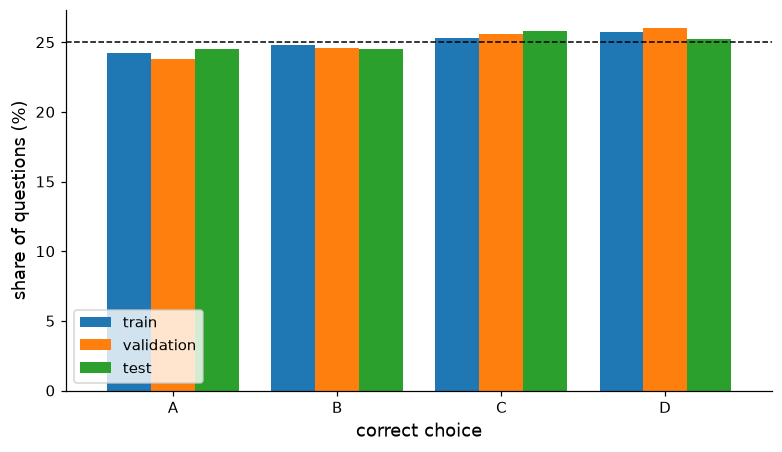

In [10]:
letters = lab['correct_choice_idx'].astype(int).map(dict(enumerate('ABCD')))
dist = pd.DataFrame({s: lab.loc[lab['split'] == s, 'correct_choice_idx'].astype(int).map(dict(enumerate('ABCD'))).value_counts(normalize=True).sort_index() * 100
                     for s in SPLITS}).round(1)
dist['all'] = (letters.value_counts(normalize=True).sort_index() * 100).round(1)
display(dist)
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
dist[list(SPLITS)].plot.bar(ax=ax, width=0.8)
ax.axhline(25, color='k', ls='--', lw=1)
ax.set(xlabel='correct choice', ylabel='share of questions (%)'); ax.tick_params(axis='x', rotation=0)
save(fig, 'answer_letters.png')
plt.show()

In [11]:
def norm(t):
    return ' '.join(words(t))

correct_text = [norm(c[i]) for c, i in zip(lab['choices'], lab['correct_choice_idx'].astype(int))]
direct = [[norm(x) for x in d] for d in lab['direct_answers']]
lab['mc_in_direct'] = [a in d for a, d in zip(correct_text, direct)]
lab['top_count'] = [Counter(d).most_common(1)[0][1] for d in direct]
lab['mc_votes'] = [d.count(a) for a, d in zip(correct_text, direct)]
print('MC answer among the 10 direct answers: %.1f%%' % (lab['mc_in_direct'].mean() * 100))
print('mean number of direct answers equal to the MC answer: %.2f' % lab['mc_votes'].mean())
display(lab['top_count'].describe().round(2).to_frame('annotators giving the most common answer'))
display((lab['top_count'].value_counts(normalize=True).sort_index() * 100).round(1).to_frame('share (%)').T)
print('most common direct answer given by <=3 of 10: %.1f%%' % ((lab['top_count'] <= 3).mean() * 100))
print('most common direct answer is the MC answer: %.1f%%' % (np.mean([Counter(d).most_common(1)[0][0] == a for a, d in zip(correct_text, direct)]) * 100))
print('difficult_direct_answer share:'); display((lab.groupby('split')['difficult_direct_answer'].mean() * 100).round(1).to_frame('%').T)
print('overall: %.1f%%' % (lab['difficult_direct_answer'].mean() * 100))

MC answer among the 10 direct answers: 100.0%
mean number of direct answers equal to the MC answer: 3.74


,annotators giving the most common answer
count,18201.00
mean,4.98
std,2.35
min,1.00
25%,3.00
50%,5.00
75%,7.00
max,10.00


top_count,1,2,3,4,5,6,7,8,9,10
share (%),2.8,13.4,16.2,14.2,13.6,13.2,11.0,6.6,3.6,5.4


most common direct answer given by <=3 of 10: 32.4%
most common direct answer is the MC answer: 49.5%
difficult_direct_answer share:


split,test,train,validation
%,6.1,9.1,8.6


overall: 8.9%


**Observation and comment**

The correct letter is almost uniform. Over all 18,201 questions it is A 24.2%, B 24.8%, C 25.4% and D 25.7%. In train it is 24.2 / 24.8 / 25.3 / 25.7, in validation 23.8 / 24.6 / 25.6 / 26.0 and in test 24.5 / 24.5 / 25.8 / 25.2. The correct choice is among the 10 direct answers for 100.0% of the questions (after lowercasing and removing punctuation). On average 3.74 of the 10 annotators gave the same text as the correct choice. Direct answers do not agree strongly: the most common direct answer is given by 4.98 annotators on average (median 5). It is given by only 1 or 2 annotators for 16.2% of questions (2.8% + 13.4%), by at most 3 annotators for 32.4%, and by all 10 for 5.4%. The most common direct answer is the same as the correct choice for 49.5% of the questions. `difficult_direct_answer` is 8.9% overall (9.1% train, 8.6% validation, 6.1% test).

## 7. Pair quality

Look at random training samples, then check how well the rationale and the answer fit the question. Rationales are written by crowd workers, so some are noisy.

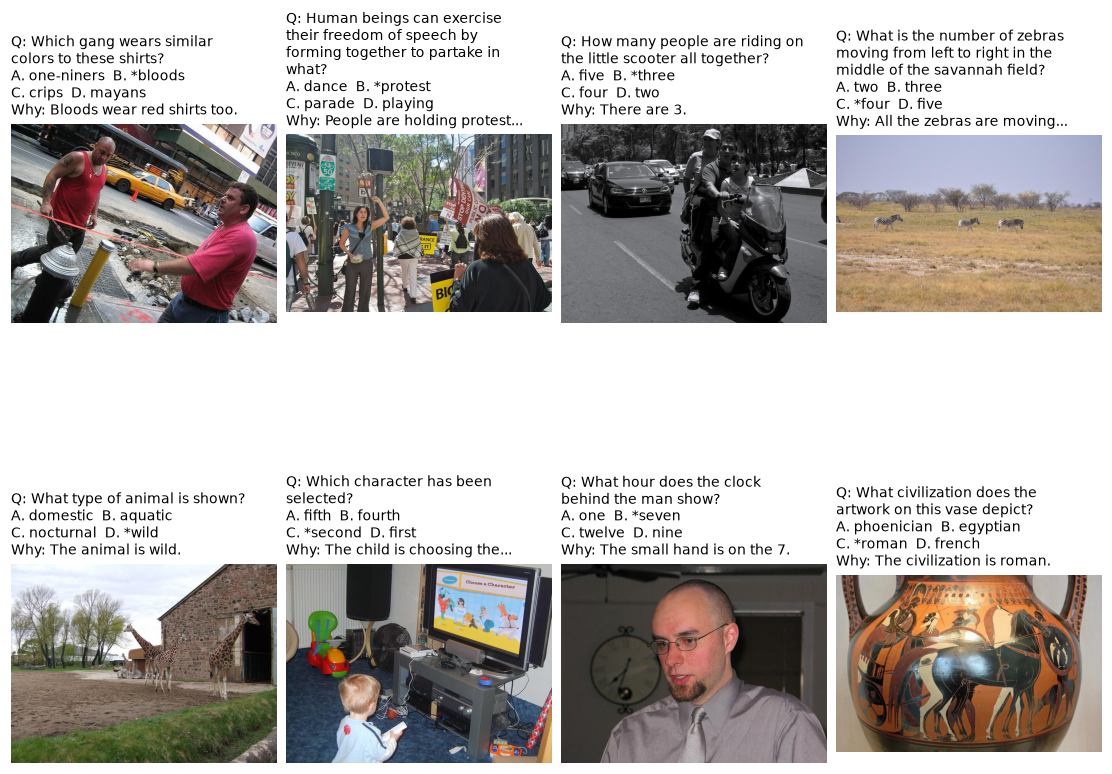

In [12]:
def show(ax, row, mark=True):
    im = Image.open(BytesIO(row['image'])).convert('RGB')
    ax.imshow(im); ax.axis('off')
    lines = textwrap.wrap('Q: ' + row['question'], 32)
    opts = ['%s. %s%s' % ('ABCD'[i], '*' if i == row['correct_choice_idx'] else '', c) for i, c in enumerate(row['choices'])]
    lines += ['  '.join(opts[:2]), '  '.join(opts[2:])]
    lines.append(textwrap.shorten('Why: ' + row['rationales'][0], 34, placeholder='...'))
    ax.set_title('\n'.join(lines), fontsize=9, loc='left')

rng = np.random.RandomState(SEED)
pick = train.iloc[rng.choice(len(train), 8, replace=False)]
fig, axes = plt.subplots(2, 4, figsize=(10, 8), layout='constrained')
for ax, (_, row) in zip(axes.ravel(), pick.iterrows()):
    show(ax, row)
save(fig, 'samples.png')
plt.show()

**Observation and comment**

The 8 random training samples show the usual mix. Some need a bit of knowledge (a vase with a Roman scene, a hand on the 7 of a clock), some are simple counting (three people on a scooter) and some depend on the choices (`wild` for 'What type of animal is shown?'). Several rationales only restate the answer ('The animal is wild.'), so they are weak as explanations.

In [13]:
# does a rationale mention a word of the correct choice
stop = set('a an the of in on at to is are it its and or for with this that be as by from'.split())
hit = []
for (_, r) in lab.iterrows():
    ans = set(words(r['choices'][int(r['correct_choice_idx'])])) - stop
    hit.append([bool(ans & set(words(x))) for x in r['rationales']])
hit = np.array(hit)
print('rationales that mention a word of the correct choice: %.1f%%' % (hit.mean() * 100))
print('questions where at least one of the 3 rationales does: %.1f%%' % (hit.any(axis=1).mean() * 100))
print('questions where none does: %.1f%%' % ((~hit.any(axis=1)).mean() * 100))

rationales that mention a word of the correct choice: 42.9%
questions where at least one of the 3 rationales does: 76.8%
questions where none does: 23.2%


train questions with both signals: 0
train questions with either signal: 5041 (32.8% of train)
train questions with top direct answer <=3 of 10: 5041
train questions with MC answer not in direct answers: 0


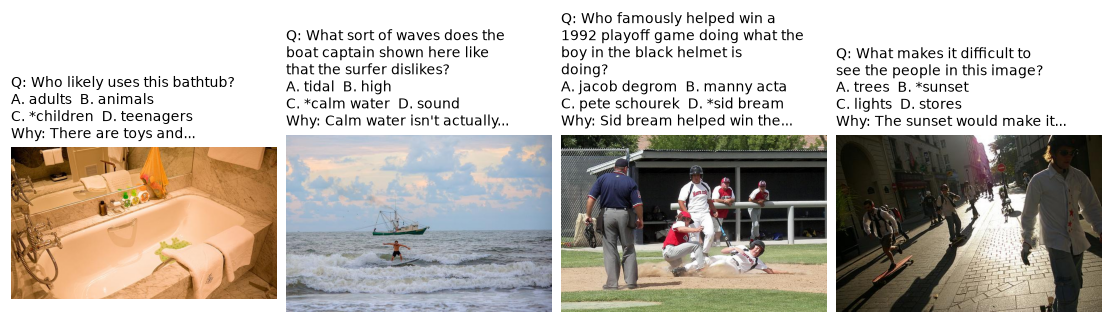

In [14]:
# possible noise: weak direct answer agreement, or the MC answer is not in the direct answers
lab_cols = lab[['question_id', 'top_count', 'mc_in_direct']]
train = train.drop(columns=[c for c in ['top_count', 'mc_in_direct'] if c in train]).merge(lab_cols, on='question_id')
val = val.drop(columns=[c for c in ['top_count', 'mc_in_direct'] if c in val]).merge(lab_cols, on='question_id')
both = (train['top_count'] <= 3) & (~train['mc_in_direct'])
cand = train[(train['top_count'] <= 3) | (~train['mc_in_direct'])]
print('train questions with both signals:', both.sum())
print('train questions with either signal:', len(cand), '(%.1f%% of train)' % (len(cand) / len(train) * 100))
print('train questions with top direct answer <=3 of 10:', (train['top_count'] <= 3).sum())
print('train questions with MC answer not in direct answers:', (~train['mc_in_direct']).sum())
pick = cand.sample(4, random_state=SEED)
fig, axes = plt.subplots(1, 4, figsize=(10, 4.5), layout='constrained')
for ax, (_, row) in zip(axes, pick.iterrows()):
    show(ax, row)
save(fig, 'noisy.png')
plt.show()

**Observation and comment**

A rationale mentions a word of the correct choice in 42.9% of the 54,603 rationales. At least one of the 3 rationales does so for 76.8% of the questions, and none does for 23.2%. This is a crude check, because many rationales explain with other words (for example 'There are 3.' for 'three'). For possible noise, the MC answer is always among the direct answers (0 train questions fail this), and 5,041 train questions (32.8%) have a most common direct answer given by at most 3 of 10 annotators. The 4 samples above are drawn from those 5,041. They are only possibly noisy. Some are open questions with several fair answers (who uses a bathtub), and one asks about a person whose name cannot be read from the image (the 1992 playoff question needs outside facts). We do not remove any of them.

## 8. Preliminary bias checks

Five rules that use only text or position. They are fitted on our train split and scored on our validation split. The official validation split (our test) is not used here. They are not the planned baselines. They show how much a model could get without looking at the image.

In [15]:
def acc(pred, y):
    return float(np.mean(np.array(pred) == np.array(y)))

y_val = val['correct_choice_idx'].astype(int).tolist()
y_tr = train['correct_choice_idx'].astype(int).tolist()
results = {}
results['(a) chance, 4 choices'] = 0.25
# (b) most frequent letter in train
top = Counter(y_tr).most_common(1)[0][0]
results['(b) always letter %s' % 'ABCD'[top]] = acc([top] * len(val), y_val)
# (c) answer text prior: how often a choice text was the correct one in train
right = Counter(norm(c[i]) for c, i in zip(train['choices'], y_tr))
def prior_pick(c):
    scores = [right.get(norm(x), 0) for x in c]
    return int(np.argmax(scores))
results['(c) answer-text prior'] = acc([prior_pick(c) for c in val['choices']], y_val)
# (d) choice sharing most words with the question
def overlap_pick(q, c):
    qw = set(words(q)) - stop
    return int(np.argmax([len(qw & set(words(x))) for x in c]))
results['(d) question-choice overlap'] = acc([overlap_pick(q, c) for q, c in zip(val['question'], val['choices'])], y_val)
# (e) longest choice
results['(e) longest choice'] = acc([int(np.argmax([len(x) for x in c])) for c in val['choices']], y_val)
res = pd.Series(results, name='validation accuracy').to_frame()
res['accuracy (%)'] = (res['validation accuracy'] * 100).round(1)
display(res)
seen = np.mean([any(right.get(norm(x), 0) > 0 for x in c) for c in val['choices']])
print('validation questions where at least one choice text was a correct answer in train: %.1f%%' % (seen * 100))
print('validation size:', len(val))

,validation accuracy,accuracy (%)
"(a) chance, 4 choices",0.250000,25.0
(b) always letter D,0.260234,26.0
(c) answer-text prior,0.310526,31.1
(d) question-choice overlap,0.240936,24.1
(e) longest choice,0.284795,28.5


validation questions where at least one choice text was a correct answer in train: 89.6%
validation size: 1710


**Observation and comment**

On the 1,710 validation questions the rules score: chance 25.0%, always the most frequent train letter (D) 26.0%, answer-text prior 31.1%, question-choice word overlap 24.1% and longest choice 28.5%. The answer-text prior is the strongest, 6.1 points above chance. For 89.6% of validation questions at least one choice text was a correct answer somewhere in train, so the prior has something to use. The letter rule and word overlap are near chance, so the letters are well balanced. The longest-choice rule gets 3.5 points over chance. Text alone is therefore weak but not zero, and a model that sees the question and choices without the image may get above 31%.

## 9. Preprocessing check

Resize to 224 x 224 with bicubic interpolation, then normalise with the CLIP mean and standard deviation. Show one image before and after, and one batch from the data loader.

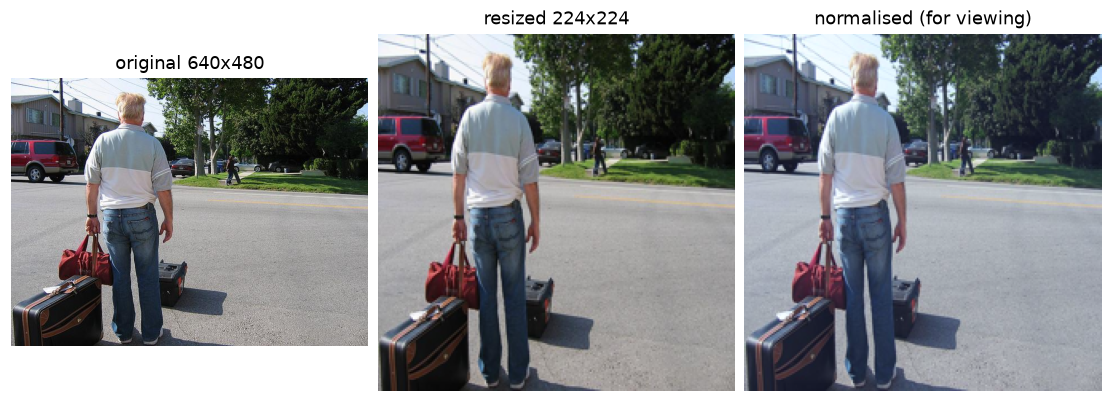

   mean before  std before  mean after  std after
R        0.442       0.266      -0.148      0.991
G        0.445       0.260      -0.051      0.995
B        0.437       0.269       0.104      0.976


In [16]:
from data_loader import get_data_loaders, AOKVQADataset, MEAN, STD
row = train.iloc[0]
data = AOKVQADataset(train.iloc[:1])
x, q, c, y = data[0]
orig = Image.open(BytesIO(row['image'])).convert('RGB')
shown = (x * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)).clamp(0, 1).permute(1, 2, 0).numpy()
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6), layout='constrained')
ax[0].imshow(orig); ax[0].set_title('original %dx%d' % orig.size); ax[0].axis('off')
ax[1].imshow(shown); ax[1].set_title('resized 224x224'); ax[1].axis('off')
ax[2].imshow(x.permute(1, 2, 0).numpy().clip(-2, 2) / 4 + 0.5); ax[2].set_title('normalised (for viewing)'); ax[2].axis('off')
save(fig, 'preprocessing.png')
plt.show()
rgb = np.asarray(orig.resize((224, 224), Image.BICUBIC)) / 255
print(pd.DataFrame({'mean before': rgb.mean((0, 1)), 'std before': rgb.std((0, 1)),
                    'mean after': x.mean((1, 2)).numpy(), 'std after': x.std((1, 2)).numpy()}, index=list('RGB')).round(3))

In [17]:
train_loader, val_loader, test_loader = get_data_loaders(batch_size=32, seed=SEED)
images, questions, choices_b, labels_b = next(iter(train_loader))
print('split sizes:', len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))
print('images', tuple(images.shape), images.dtype, '| labels', tuple(labels_b.shape), labels_b.dtype)
print('batch pixel mean per channel', images.mean((0, 2, 3)).numpy().round(3), 'std', images.std((0, 2, 3)).numpy().round(3))
print(questions[0], choices_b[0], labels_b[0].item())

split sizes: 15346 1710 1145
images (32, 3, 224, 224) torch.float32 | labels (32,) torch.int64
batch pixel mean per channel [-0.061 -0.087 -0.016] std [1.07  1.083 1.061]
What type of establishment in the background is it? ['hotel', 'furniture room', 'restaurant', 'bank'] 1


**Observation and comment**

The image goes from its original size to 224 x 224 with bicubic resizing. After CLIP normalisation the example image has per-channel means of -0.148, -0.051 and 0.104 (R, G, B) and standard deviations of 0.991, 0.995 and 0.976, close to 0 and 1. Before normalisation the means were 0.442, 0.445 and 0.437. A batch from the loader has images of shape (32, 3, 224, 224) in float32, labels of shape (32,) in int64, 32 question strings and 32 lists of 4 choices. Over the batch the channel means are -0.061, -0.087 and -0.016 and the standard deviations about 1.07, 1.08 and 1.06. The loader sizes are 15,346 / 1,710 / 1,145 for train, validation and test.

## 10. EDA conclusions

- No image is shared between the official splits, but 517 train images carry two questions. We split by image hash so that no image appears in two of our splits (0 overlaps checked).
- The test split has no labels (6,702 unlabelled questions). We use the official validation split (1,145 questions) as our test set.
- There are 18,201 labelled pairs and 15,346 in our train split, so the handbook threshold of at least 10,000 VQA pairs is met.
- Data quality is good: no missing or undecodable images and no invalid labels. Only 7 empty choices, 37 duplicate-choice questions and 2 empty direct answers, so we keep all rows.
- The answer letters are balanced (24.2 to 25.7%), so letter position gives no shortcut (26.0%).
- The answer-text prior reaches 31.1% and the longest-choice rule 28.5%, against 25.0% chance. We will report a text-only baseline next to the image models, so we can see what the image adds.
- The correct choice is always among the 10 direct answers, and 32.4% of questions have low agreement among annotators (at most 3 of 10). We train and score on the multiple-choice label only.
- The three rationales per question (mean 11.1 words) are short, and 23.2% of questions have no rationale that mentions the answer words. We use them for error analysis and not as a training target.
- Images are COCO photos with a median size of 640 x 480, so resizing to 224 x 224 loses detail. Small objects may be hard for the model.
- Licence: A-OKVQA is Apache 2.0 and the COCO images keep their own Flickr and CC terms, so we use the data for coursework only.